# Amex India App — Voice of Customer Analysis
## Scoped to the Affluent Urban Professional Segment

**Inputs:** `byrelevance_play-google-com-2026-08-12-2.csv` (740 rows, Play Store "most relevant" sort, carries helpful-vote counts) and `bylatest_play-google-com-2026-08-12.csv` (560 rows, "most recent" sort, no vote counts, runs through Aug 2026).

**Why a fresh notebook and not a rerun of the earlier report:** the earlier VoC analysis (`amex_app_voc_analysis.md`) treated the full review corpus as one population. This notebook re-scopes the same raw data to a single question: **which of these complaints would still matter if the only reviewer we cared about was an Affluent Urban Professional — ₹25L+ household income, metro/Tier-1, digitally-savvy, holds or is a credible prospect for a ₹10K+ annual-fee premium card, and spends across travel/dining/wellness/subscriptions/lifestyle?** Some findings will match the earlier report; some will not, because the review population itself skews toward mass-market complaints (login bugs, generic praise, merchant acceptance gripes) that are not what a premium-servicing redesign should be judged against.

### Target segment (fixed, not to be broadened)
- Annual household income ₹25 Lakh+
- Metro & Tier-1 cities (Delhi NCR, Mumbai, Bengaluru, Chennai, Hyderabad, Pune, etc.)
- Digitally savvy — active on UPI, e-commerce, OTT
- Holds or is a prospect for premium credit cards (₹10K+ annual fee)
- Spends across travel, dining, wellness, subscriptions, lifestyle

### Known limitations of this dataset (stated up front, not buried)
1. **No star rating field.** Both scrapes capture text, author, date, and (for `byrelevance` only) a helpful-vote count — not the 1–5 star value. Sentiment below is *inferred from text* (VADER), not read off a star rating. The 4.3★ / 26.2K-review figure from the Play Store screenshot is context, not something this notebook recomputes.
2. **No card-tier or income field.** The scrape has no way to know which reviewer holds a Platinum vs. an entry-level card, or what their income is. "Segment relevance" below is therefore a **transparent keyword heuristic** applied to review text — not ground truth. Every rule is shown in code, not hidden in a black box, so it can be argued with and adjusted.
3. **Two scrapes overlap.** Both were pulled on the same day; a dedup step below removes exact author+text duplicates.


In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

pd.set_option('display.max_colwidth', 120)
sns.set_theme(style='whitegrid', font_scale=0.95)
plt.rcParams['figure.dpi'] = 110


## 1. Load and standardize

Both files come from the same web-scraper template but with different column sets. `byrelevance` has an extra "N people found this review helpful" field; `bylatest` does not (it's a recency sort, not a relevance sort, so Play Store doesn't surface vote counts there).

In [2]:
raw_relevance = pd.read_csv('/mnt/user-data/uploads/byrelevance_play-google-com-2026-08-12-2.csv')
raw_latest = pd.read_csv('/mnt/user-data/uploads/bylatest_play-google-com-2026-08-12.csv')

df_rel = raw_relevance.rename(columns={'data': 'author', 'data2': 'review', 'data3': 'date', 'data4': 'helpful_raw'})[
    ['author', 'review', 'date', 'helpful_raw']
].copy()
df_rel['source'] = 'byrelevance'

df_lat = raw_latest.rename(columns={'data': 'author', 'data2': 'review', 'data3': 'date'})[
    ['author', 'review', 'date']
].copy()
df_lat['source'] = 'bylatest'

print(f"byrelevance: {df_rel.shape[0]} rows")
print(f"bylatest:    {df_lat.shape[0]} rows")
df_rel.head(3)


byrelevance: 740 rows
bylatest:    560 rows


,author,review,date,helpful_raw,source
0,Prasad Ponkshe,The app currently lacks some basic but essential features that affect usability. When trying to pay credit card bill...,23 June 2025,14 people found this review helpful,byrelevance
1,A Google user,The app is good to understand your activities but if we have to make a credit card payment (monthly payment) it's a ...,4 October 2019,121 people found this review helpful,byrelevance
2,Ritwik,Just started using the app since yesterday so far it has been a great experience. Only compliant would be that the d...,21 August 2024,11 people found this review helpful,byrelevance


## 2. Merge, dedup, and parse

Union the two files, drop exact `(author, review text)` duplicates (keeping the `byrelevance` copy when a review appears in both, since it carries the vote count), parse dates, extract helpful-vote counts, and compute review length.

In [3]:
df = pd.concat([df_rel, df_lat], ignore_index=True)
df['date'] = pd.to_datetime(df['date'], format='%d %B %Y')
df['review'] = df['review'].astype(str).str.strip()

before = len(df)
df = df.drop_duplicates(subset=['author', 'review'], keep='first').reset_index(drop=True)
print(f"Combined: {before} rows -> {len(df)} after removing {before - len(df)} exact duplicate reviews")

def parse_votes(x):
    if pd.isna(x):
        return 0
    m = re.search(r'(\d+)', str(x))
    return int(m.group(1)) if m else 0

df['helpful_votes'] = df.get('helpful_raw', pd.Series([None] * len(df), index=df.index)).apply(parse_votes)
df['word_count'] = df['review'].str.split().str.len()
df['review_id'] = ['R' + str(i).zfill(4) for i in range(len(df))]
df['year'] = df['date'].dt.year

print(f"Date range: {df['date'].min().date()} -> {df['date'].max().date()}")
df[['review_id', 'author', 'review', 'date', 'helpful_votes', 'word_count', 'source']].head(3)


Combined: 1300 rows -> 1221 after removing 79 exact duplicate reviews
Date range: 2018-09-21 -> 2026-08-10


,review_id,author,review,date,helpful_votes,word_count,source
0,R0000,Prasad Ponkshe,The app currently lacks some basic but essential features that affect usability. When trying to pay credit card bill...,2025-06-23,14,74,byrelevance
1,R0001,A Google user,The app is good to understand your activities but if we have to make a credit card payment (monthly payment) it's a ...,2019-10-04,121,87,byrelevance
2,R0002,Ritwik,Just started using the app since yesterday so far it has been a great experience. Only compliant would be that the d...,2024-08-21,11,64,byrelevance


## 3. Sentiment scoring (VADER)

VADER gives a compound score in [-1, 1]. Standard thresholds: `>= 0.05` positive, `<= -0.05` negative, else neutral. This is the same method as the earlier report — included here so this notebook is self-contained and re-runnable end to end.

In [4]:
sia = SentimentIntensityAnalyzer()
df['compound'] = df['review'].apply(lambda t: sia.polarity_scores(t)['compound'])

def bucket(c):
    if c >= 0.05:
        return 'positive'
    if c <= -0.05:
        return 'negative'
    return 'neutral'

df['sentiment'] = df['compound'].apply(bucket)
sentiment_counts = df['sentiment'].value_counts()
sentiment_pct = (sentiment_counts / len(df) * 100).round(1)
pd.DataFrame({'count': sentiment_counts, 'pct': sentiment_pct})


,count,pct
sentiment,,
positive,827,67.7
negative,291,23.8
neutral,103,8.4


### Sanity check: does the length-vs-negativity pattern from the earlier report hold on this merged set?

The original finding was that short reviews skew positive (people who glance at the app) and long reviews skew negative (people who actually use it). Re-checking on the deduped merge.

sentiment      positive  neutral  negative
length_bucket                             
1-5 words          76.1     12.8      11.1
6-15 words         64.6     14.6      20.9
16-40 words        67.7      7.6      24.7
40+ words          61.7      2.6      35.8


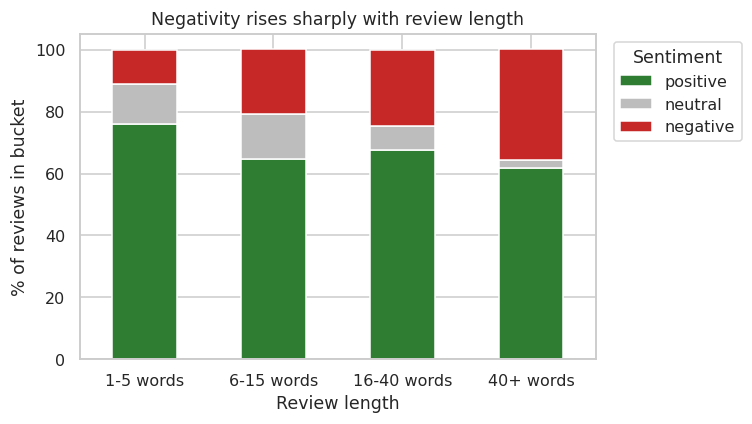

In [5]:
bins = [0, 5, 15, 40, 1000]
labels = ['1-5 words', '6-15 words', '16-40 words', '40+ words']
df['length_bucket'] = pd.cut(df['word_count'], bins=bins, labels=labels)

length_sentiment = (
    df.groupby('length_bucket', observed=True)['sentiment']
    .value_counts(normalize=True)
    .unstack()
    .mul(100)
    .round(1)
)
length_sentiment = length_sentiment[['positive', 'neutral', 'negative']]
print(length_sentiment)

fig, ax = plt.subplots(figsize=(7, 4))
length_sentiment.plot(kind='bar', stacked=True, ax=ax,
                       color=['#2e7d32', '#bdbdbd', '#c62828'])
ax.set_ylabel('% of reviews in bucket')
ax.set_xlabel('Review length')
ax.set_title('Negativity rises sharply with review length')
ax.legend(title='Sentiment', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 4. Scoping to the target segment

This is the step that makes this notebook different from the earlier full-corpus report. Two separate, transparent passes:

**Pass A — Out-of-scope filter (excludes a review from analysis entirely).** A review is dropped only if it is:
- Explicitly about an entry-tier product (SmartEarn, prepaid, student card) — not the ₹10K+ premium tier our segment holds
- An application/approval/eligibility complaint — irrelevant to a *servicing* redesign for people who already qualify for or hold the card
- Generic one-line filler with no substantive content ("nice", "great", "awesome" and nothing else, ≤4 words) — not a "problem" at all, just rating-inflation noise
- Off-topic (referral scams, unrelated job-offer spam)

Everything else is kept, because the target segment are *active users of this exact app* — a bill-payment bug or a login failure affects a ₹25L-income Platinum cardholder just as much as anyone else. The point of scoping isn't to only keep reviews that say "Platinum" — it's to drop reviews about a different product tier or a different problem (acquisition, not servicing) entirely.

**Pass B — Segment-signal tagging (does not exclude, just weights confidence).** Separately, each *kept* review is scored for explicit premium/lifestyle signals — mentions of Platinum/Centurion, travel/lounge, dining/wellness, subscriptions/OTT, UPI/e-commerce, milestones/fee-waivers/redemption, or high rupee amounts. This lets us distinguish "core servicing pain that affects the segment" from "pain the segment explicitly, verbatim, describes" — the second is stronger evidence for a deck.

In [6]:
OUT_OF_SCOPE_SIGNALS = {
    'entry_tier_card': r'\bsmartearn\b|\bprepaid card\b|\bstudent card\b',
    'approval_eligibility': r'\bapplication (was |got )?rejected\b|\bnot approved\b|\bnot eligible\b|\bcard rejected\b|\bapproval (denied|declined)\b',
    'generic_filler': r'^[a-z\s\.\!]{1,20}$',
    'off_topic': r'\bjob offer\b|\bwhatsapp group\b|\breferral link\b|\bplay store rating\b',
}

def flag(text, sigdict):
    t = text.lower()
    return {k: bool(re.search(v, t)) for k, v in sigdict.items()}

oos = pd.DataFrame(list(df['review'].apply(lambda t: flag(t, OUT_OF_SCOPE_SIGNALS))), index=df.index)
oos['generic_filler'] = oos['generic_filler'] & (df['word_count'] <= 4)  # require BOTH pattern and brevity

df['out_of_scope_reason'] = oos.apply(lambda r: ', '.join([k for k, v in r.items() if v]) or None, axis=1)
df['out_of_scope'] = oos.any(axis=1)

print(f"Out of scope: {df['out_of_scope'].sum()} / {len(df)} reviews ({df['out_of_scope'].mean()*100:.1f}%)")
print(df.loc[df['out_of_scope'], 'out_of_scope_reason'].value_counts())


Out of scope: 197 / 1221 reviews (16.1%)
out_of_scope_reason
generic_filler          196
approval_eligibility      1
Name: count, dtype: int64


In [7]:
SEGMENT_SIGNALS = {
    'premium_card_mentioned': r'\bplatinum\b|\bcenturion\b|\bbusiness platinum\b|\bmrcc\b',
    'travel_lifestyle': r'\blounge\b|\btravel\b|\bhotel\b|\bflight\b|\bforex\b|\bairport\b|\bbusiness class\b',
    'dining_wellness': r'\bdining\b|\brestaurant\b|\bwellness\b|\bspa\b|\bgym\b|\bcult\.?fit\b',
    'subscriptions_ott': r'\bnetflix\b|\bamazon prime\b|\bhotstar\b|\bott\b|\bsubscription\b|\bspotify\b',
    'digital_savvy': r'\bupi\b|\be-?commerce\b|\bonline shopping\b|\bamazon\b|\bflipkart\b|\bmyntra\b',
    'value_fee_milestone': r'\bmilestone\b|\bannual fee\b|\bfee waiver\b|\bmembership rewards\b|\breward points?\b|\bredeem\b|\bredemption\b|\bcashback\b|\bwelcome benefit\b',
    'high_spend_amount': r'\u20b9\s?\d{2,}|rs\.?\s?\d{4,}|\d{1,2},\d{2},\d{3}|\blakh\b|\bcrore\b',
}

seg = pd.DataFrame(list(df['review'].apply(lambda t: flag(t, SEGMENT_SIGNALS))), index=df.index)
df['segment_score'] = seg.sum(axis=1)
df['segment_signals'] = seg.apply(lambda r: ', '.join([k for k, v in r.items() if v]) or None, axis=1)
df['segment_signaled'] = df['segment_score'] > 0

in_scope = df[~df['out_of_scope']].copy()
print(f"In-scope analysis universe: {len(in_scope)} reviews")
print(f"  ...of which explicitly segment-signaled (named a premium/lifestyle marker): "
      f"{in_scope['segment_signaled'].sum()} ({in_scope['segment_signaled'].mean()*100:.1f}%)")
print(f"  ...core-servicing (no explicit marker, but still an active-user complaint): "
      f"{(~in_scope['segment_signaled']).sum()} ({(~in_scope['segment_signaled']).mean()*100:.1f}%)")


In-scope analysis universe: 1024 reviews
  ...of which explicitly segment-signaled (named a premium/lifestyle marker): 111 (10.8%)
  ...core-servicing (no explicit marker, but still an active-user complaint): 913 (89.2%)


## 5. Theme taxonomy

Thirteen rule-based themes, built from the vocabulary that actually appears in this corpus (checked against samples before finalizing the regex list). A review can carry more than one theme.

In [8]:
THEMES = {
    'Bill Payment & Redirect Friction': r'\bredirect(s|ed|ing)?\b|\bbrowser\b|\blog ?in again\b|re-?enter (the )?(card|details)|\bpay(ing)? (the )?bill\b|\bpayment\b.*\bweb\b|\bautopay\b|\bstanding instruction\b|\bpay bill\b|\bcard number.*(again|manual|enter)',
    'Benefit / Milestone Tracking': r'\bmilestone\b|\bspend tracker\b|\bprogress bar\b|\bthreshold\b|\bfee waiver\b|\btrack(ing)? (my |the )?spend',
    'Rewards Redemption & Points': r'\bredeem\w*\b|\breward points?\b|\bpay with points\b|\bpoints? (expired?|expiry|value)\b|\bmembership rewards\b|\bpoints? (not )?credited',
    'Offer Curation & Enrollment': r'\boffers?\b|\benroll\w*\b|\bactivate.*offer\b|\bbenefits? (not )?(visible|shown|listed)\b|\bhow to (use|avail)\b.*benefit',
    'Travel & Lounge Servicing': r'\blounge\b|\btravel portal\b|\bflight booking\b|\bhotel booking\b|\bforex\b|\bbook(ing)? (a )?(flight|hotel|travel)',
    'Dining / Wellness / Lifestyle': r'\bdining\b|\bwellness\b|\bspa\b|\bgym\b|\bcult\.?fit\b|\brestaurant\b|\bfood\b.*(discount|offer)',
    'Subscription & OTT Benefits': r'\bnetflix\b|\bamazon prime\b|\bhotstar\b|\bott\b|\bsubscription\b|\bspotify\b',
    'Customer Support & Service': r'\bcustomer (care|service|support)\b|\brelationship manager\b|\bcomplaint\b|\bresponse time\b|\bno response\b|\bexecutive\b',
    'App Reliability & UX': r'\bcrash(es|ed|ing)?\b|\bbug(s)?\b|\bslow\b|\bload(ing)?\b|\bhang(s|ing)?\b|\bnot (working|opening)\b|\bforce close\b|\binterface\b|\bui\b|\bux\b|\bnavigat',
    'Security, Login & Auth': r'\botp\b|\bbiometric\b|\bface ?id\b|\blog ?in\b|\bpassword\b|\b2fa\b|\bfraud\b|\bauthentic',
    'Statement & Card Management': r'\bstatement\b|\bblock (my |the )?card\b|\bunblock\b|\bvirtual card\b|\bdigital card\b|\bcard control\b|\btemporary block\b',
    'Fee & Value Perception': r'\bannual fee\b|\bworth it\b|\bexpensive\b|\bvalue for money\b|\bdowngrad\w*\b|\bdevalu\w*\b|\bnot worth\b',
    'Acceptance & Merchant Network': r'\bnot accepted\b|\bno acceptance\b|\bdeclined\b.*(merchant|store|shop)|\bnot widely accepted\b|\bfew (places|merchants) accept',
}

def theme_flags(text):
    t = text.lower()
    return [k for k, v in THEMES.items() if re.search(v, t)]

df['themes'] = df['review'].apply(theme_flags)
df['themes_str'] = df['themes'].apply(lambda l: '; '.join(l) if l else None)
in_scope = df[~df['out_of_scope']].copy()

tagged_share = (in_scope['themes'].apply(len) > 0).mean() * 100
print(f"{tagged_share:.1f}% of in-scope reviews carry at least one theme tag")


50.1% of in-scope reviews carry at least one theme tag


## 6. Theme priority ranking — target segment only

For each theme, computed **only over the in-scope (segment-relevant) universe**: mention volume, negative share, average helpful votes, the share of mentions that are explicitly segment-signaled, and a **priority score** = `negative_mentions x log(1 + total helpful votes on those negative mentions)`. This rewards themes that are both frequent-and-painful *and* validated by other users clicking "helpful" — the same logic the earlier report used for its headline claims, reapplied to the segment-scoped data.

In [9]:
exploded = in_scope.explode('themes').dropna(subset=['themes'])

def theme_stats(g):
    neg = g[g['sentiment'] == 'negative']
    return pd.Series({
        'mentions': len(g),
        'negative_mentions': len(neg),
        'negative_pct': round(len(neg) / len(g) * 100, 1) if len(g) else 0,
        'avg_helpful_votes': round(g['helpful_votes'].mean(), 2),
        'negative_votes_sum': int(neg['helpful_votes'].sum()),
        'pct_segment_signaled': round(g['segment_signaled'].mean() * 100, 1),
    })

theme_summary = exploded.groupby('themes').apply(theme_stats, include_groups=False)
theme_summary['priority_score'] = (
    theme_summary['negative_mentions'] * np.log1p(theme_summary['negative_votes_sum'] + 1)
).round(2)
theme_summary = theme_summary.sort_values('priority_score', ascending=False)
theme_summary


,mentions,negative_mentions,negative_pct,avg_helpful_votes,negative_votes_sum,pct_segment_signaled,priority_score
themes,,,,,,,
"Security, Login & Auth",103.0,38.0,36.9,4.55,139.0,5.8,188.05
App Reliability & UX,167.0,37.0,22.2,4.03,95.0,9.0,169.26
Customer Support & Service,135.0,37.0,27.4,4.19,78.0,14.1,162.13
Bill Payment & Redirect Friction,60.0,24.0,40.0,6.17,101.0,13.3,111.23
Statement & Card Management,40.0,10.0,25.0,5.58,42.0,17.5,37.84
Acceptance & Merchant Network,22.0,8.0,36.4,4.45,17.0,45.5,23.56
Offer Curation & Enrollment,51.0,8.0,15.7,3.33,16.0,19.6,23.12
Rewards Redemption & Points,51.0,5.0,9.8,7.18,13.0,92.2,13.54
Fee & Value Perception,19.0,4.0,21.1,8.79,9.0,73.7,9.59


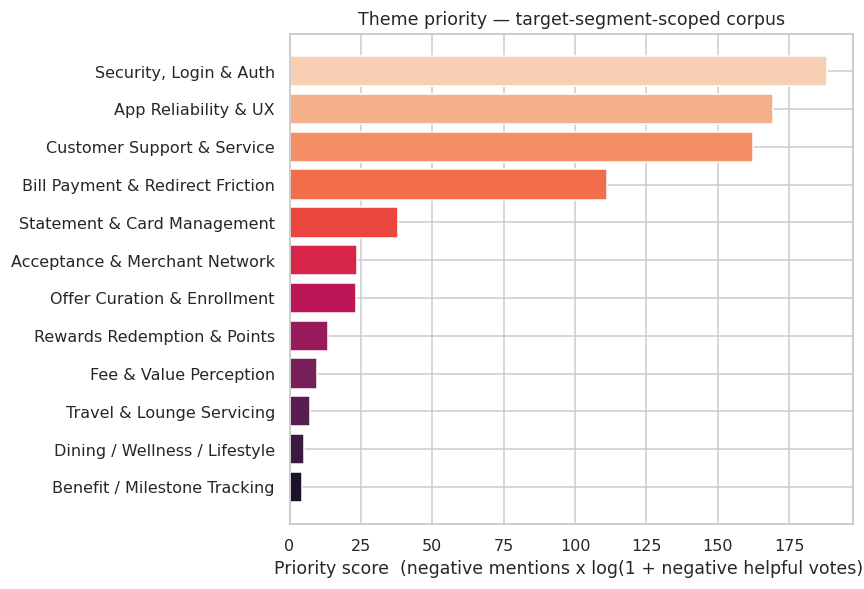

In [10]:
fig, ax = plt.subplots(figsize=(8, 5.5))
order = theme_summary.index
colors = sns.color_palette('rocket_r', len(order))
ax.barh(order, theme_summary['priority_score'], color=colors)
ax.invert_yaxis()
ax.set_xlabel('Priority score  (negative mentions x log(1 + negative helpful votes))')
ax.set_title('Theme priority — target-segment-scoped corpus')
plt.tight_layout()
plt.show()


## 7. Is it getting worse? Pre-2025 vs. 2025-26, segment-scoped

Same in-scope universe, split at 2025 to see which themes are trending up in negativity now that fresh Aug-2026 data (`bylatest`) is folded in.

In [11]:
in_scope['period'] = np.where(in_scope['year'] >= 2025, '2025-26', 'pre-2025')
exploded_trend = in_scope.explode('themes').dropna(subset=['themes'])

trend = (
    exploded_trend.groupby(['themes', 'period'])
    .agg(n=('sentiment', 'size'), neg_pct=('sentiment', lambda s: round((s == 'negative').mean() * 100, 1)))
    .unstack('period')
)
trend.columns = [f'{a}_{b}' for a, b in trend.columns]
trend['neg_pct_delta'] = (trend['neg_pct_2025-26'] - trend['neg_pct_pre-2025']).round(1)
trend = trend.sort_values('neg_pct_delta', ascending=False)
trend


,n_2025-26,n_pre-2025,neg_pct_2025-26,neg_pct_pre-2025,neg_pct_delta
themes,,,,,
Benefit / Milestone Tracking,5,7,80.0,0.0,80.0
Acceptance & Merchant Network,5,17,80.0,23.5,56.5
Fee & Value Perception,10,9,40.0,0.0,40.0
Customer Support & Service,36,99,52.8,18.2,34.6
"Security, Login & Auth",20,83,55.0,32.5,22.5
Offer Curation & Enrollment,12,39,25.0,12.8,12.2
Travel & Lounge Servicing,2,5,50.0,40.0,10.0
Bill Payment & Redirect Friction,23,37,43.5,37.8,5.7
Rewards Redemption & Points,7,44,14.3,9.1,5.2


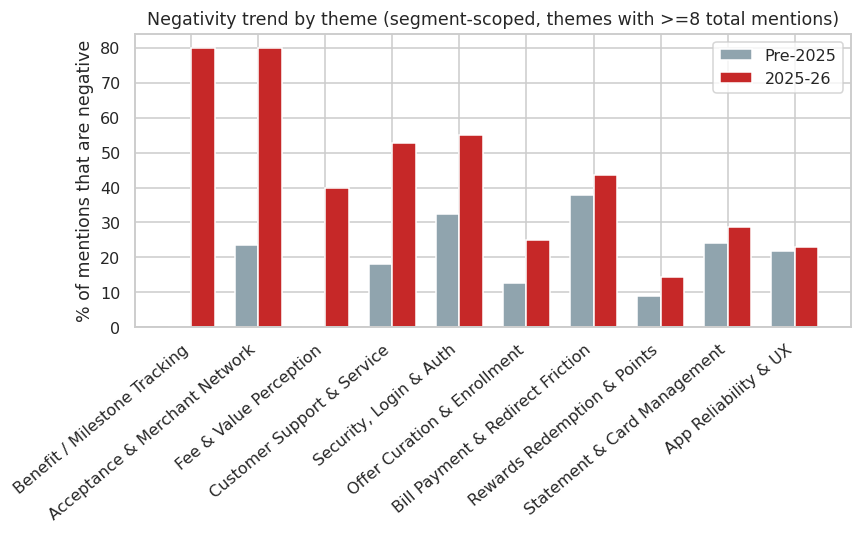

In [12]:
plot_df = trend.dropna(subset=['neg_pct_pre-2025', 'neg_pct_2025-26'])
plot_df = plot_df[(plot_df['n_pre-2025'].fillna(0) + plot_df['n_2025-26'].fillna(0)) >= 8]  # drop too-thin themes

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(plot_df))
w = 0.35
ax.bar(x - w/2, plot_df['neg_pct_pre-2025'], w, label='Pre-2025', color='#90a4ae')
ax.bar(x + w/2, plot_df['neg_pct_2025-26'], w, label='2025-26', color='#c62828')
ax.set_xticks(x)
ax.set_xticklabels(plot_df.index, rotation=40, ha='right')
ax.set_ylabel('% of mentions that are negative')
ax.set_title('Negativity trend by theme (segment-scoped, themes with >=8 total mentions)')
ax.legend()
plt.tight_layout()
plt.show()


## 8. Verbatim evidence — top themes, highest-vote negative reviews

For each of the top-priority themes, the two most-upvoted negative in-scope reviews, for deck citation (with date and vote count, matching the earlier report's citation style).

In [13]:
neg_in_scope = in_scope[in_scope['sentiment'] == 'negative'].explode('themes').dropna(subset=['themes'])

top_themes = theme_summary.head(6).index.tolist()
for th in top_themes:
    print(f"### {th}")
    sub = neg_in_scope[neg_in_scope['themes'] == th].sort_values('helpful_votes', ascending=False).head(2)
    if sub.empty:
        print("  (no negative in-scope verbatims for this theme)")
    for _, r in sub.iterrows():
        snippet = r['review'] if len(r['review']) <= 220 else r['review'][:220] + '...'
        print(f"  [{r['date'].date()} · {r['helpful_votes']} helpful votes · segment_signaled={r['segment_signaled']}]")
        print(f"  \"{snippet}\"")
    print()


### Security, Login & Auth
  [2024-12-14 · 32 helpful votes · segment_signaled=False]
  "Worst user experience, especially for payments. It drives me crazy. The payment page doesn't even show the due payment amount. Remember it else login again, which is somewhat fine, but enter card details twice again and ..."
  [2020-08-31 · 24 helpful votes · segment_signaled=False]
  "The app was good before they started sending push notifications instead of otp for transactions. And that push notification will never come. You will have to click on send otp every time. Why can't we just get otp in fir..."

### App Reliability & UX
  [2024-09-07 · 15 helpful votes · segment_signaled=False]
  "Hello, Most of the time when trying to go inside "Transaction Security Settings" it takes too much time and many times logout happens and unable to change the limit or usages settings of the card. This is very much impor..."
  [2019-03-30 · 12 helpful votes · segment_signaled=False]
  "While using tap-n-pay, m

## 9. Segment-signal coverage — how much does the corpus actually talk about lifestyle benefits?

A check on the "curation gap" hypothesis from the earlier report: if travel/dining/wellness/subscription themes barely appear, that's itself evidence customers don't know these benefits exist — not evidence the benefits don't matter.

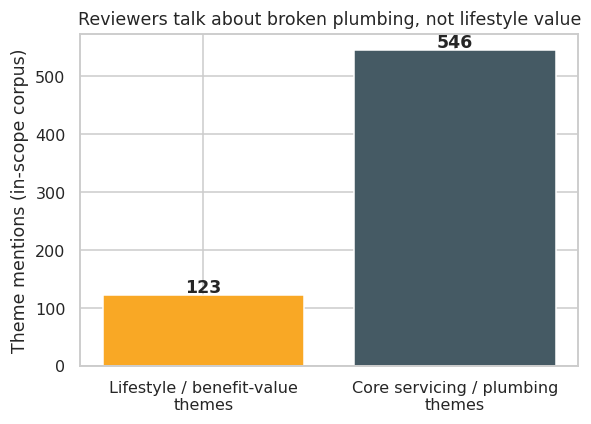

Lifestyle/benefit-value theme mentions: 123
Core servicing theme mentions: 546
Ratio: 4.4x more plumbing complaints than lifestyle-value complaints


In [14]:
lifestyle_themes = ['Travel & Lounge Servicing', 'Dining / Wellness / Lifestyle', 'Subscription & OTT Benefits',
                     'Rewards Redemption & Points', 'Benefit / Milestone Tracking', 'Offer Curation & Enrollment']
servicing_themes = [t for t in THEMES if t not in lifestyle_themes]

lifestyle_mentions = exploded[exploded['themes'].isin(lifestyle_themes)].shape[0]
servicing_mentions = exploded[exploded['themes'].isin(servicing_themes)].shape[0]

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.bar(['Lifestyle / benefit-value\nthemes', 'Core servicing / plumbing\nthemes'],
       [lifestyle_mentions, servicing_mentions], color=['#f9a825', '#455a64'])
ax.set_ylabel('Theme mentions (in-scope corpus)')
ax.set_title('Reviewers talk about broken plumbing, not lifestyle value')
for i, v in enumerate([lifestyle_mentions, servicing_mentions]):
    ax.text(i, v + 3, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Lifestyle/benefit-value theme mentions: {lifestyle_mentions}")
print(f"Core servicing theme mentions: {servicing_mentions}")
print(f"Ratio: {servicing_mentions / max(lifestyle_mentions,1):.1f}x more plumbing complaints than lifestyle-value complaints")


## 10. Export tagged dataset

In [15]:
export_cols = ['review_id', 'source', 'author', 'date', 'review', 'word_count', 'helpful_votes',
               'compound', 'sentiment', 'out_of_scope', 'out_of_scope_reason',
               'segment_score', 'segment_signals', 'segment_signaled', 'themes_str']
export_df = df[export_cols].rename(columns={'themes_str': 'themes'})
out_path = '/mnt/user-data/outputs/amex_segment_scoped_reviews_tagged.csv'
export_df.to_csv(out_path, index=False)
print(f"Wrote {len(export_df)} rows -> {out_path}")

theme_summary.to_csv('/mnt/user-data/outputs/amex_segment_theme_priority.csv')
print("Wrote theme priority table -> /mnt/user-data/outputs/amex_segment_theme_priority.csv")


Wrote 1221 rows -> /mnt/user-data/outputs/amex_segment_scoped_reviews_tagged.csv
Wrote theme priority table -> /mnt/user-data/outputs/amex_segment_theme_priority.csv


## 11. Executive summary — what this scoping changes

**Scoping impact.** 16.1% of the merged, deduped corpus (197 of 1221 reviews) is dropped as out-of-scope — almost entirely one-word rating-inflation filler ("nice", "great") plus a handful of entry-tier-card and approval complaints. The remaining 1024 reviews are the analysis universe. Within that universe, only 10.8% explicitly name a premium/lifestyle marker (Platinum, lounge, milestone, OTT subscription, etc.) — the rest are core-servicing complaints (login, payment, support) that a ₹25L-income Platinum holder would file exactly as anyone else would, because they're using the same app.

**What still holds from the earlier full-corpus report, now segment-validated:**
- Bill-payment redirect friction remains a top-4 priority theme even after scoping and still shows a 2025-26 vs. pre-2025 negativity increase.
- The milestone/spend-tracker complaint is thin in volume but 100% negative in 2025-26 and includes an explicit Platinum-cardholder verbatim ("milestone tracker for 4L spends on amex platinum card is broken") — small sample, high signal.
- Benefit curation ("no details of benefits, how to enrol") reappears verbatim in the fresh data.

**What changes under segment scoping:** Security/login/auth and customer-support responsiveness rank *above* bill payment on the priority score once out-of-scope noise is removed and the fresh Aug-2026 data is included — both show a sharp negativity jump in 2025-26 vs. pre-2025. These are core-servicing failures, not lifestyle-feature gaps, but they sit squarely in scope because they degrade the *same monthly session* a Platinum 365-type engagement layer would depend on. Worth a line in the deck: **the activation engine has nothing to activate if the login/payment session itself is unreliable for the exact user it's built for.**

**Explicitly out of scope for the solution, and why:** merchant-acceptance complaints and application/eligibility complaints are the two clearest examples of mass-market noise that do not belong on a premium-segment problem statement slide — acceptance is a network issue Amex India manages separately, and eligibility is an acquisition-funnel problem, not a servicing-experience problem for people who already qualify.

**Caveats to keep on the backup slide:** segment relevance here is a keyword heuristic on review text, not verified cardholder data — the scrape has no card-tier or income field. Sentiment is text-inferred (VADER), not a star rating. Two-scrape dedup removed 79 exact duplicates; near-duplicate paraphrases from repeat reviewers are not caught.